# LLG dynamics driven along the $ac$ bisector

This notebook simulates the semiclassical canted two-sublattice LLG model under THz fields polarized along the crystallographic $ac$ bisector. It compares a single pulse with a pair of equally polarized, time-delayed pulses, then analyses the magnetization dynamics and their FFT spectra.

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from two_spin_dynamics.llg import run_llg
from two_spin_dynamics.pulses import d2gdt2_pulse, single_thz_pulse, two_thz_pulses
from two_spin_dynamics.plotting import (
    LEGEND_STYLES, PLOT_CONFIG, PLOT_STYLES,
    plot_field_components, plot_magnetization_dynamics, plot_time_series,
)
from two_spin_dynamics.spectral_analysis import rfft_spectrum
from two_spin_dynamics.spin_hamiltonian import canted_afm_ground_state

plt.rcParams.update(PLOT_CONFIG)

## Hamiltonian parameters setup

In [4]:
# YFeO3 parameters
ham_params = {
    'Stot': 2.5, 
    'nn': 6, 
    'Jex': 4.96,
    'Dvec': np.array([0.0, 0.107, 0.0]),  # D || b
    'Kvec': np.array([0.00288, 0.0, 0.00080]),
}
S1_eq, S2_eq, beta0 = canted_afm_ground_state(ham_params)
print(f'K_a = {ham_params["Kvec"][0]:.6f} meV; K_c = {ham_params["Kvec"][2]:.6f} meV')
print(f'beta_0 = {np.degrees(beta0):.5f} deg')
print(f'M_eq = {S1_eq + S2_eq}')

K_a = 0.002880 meV; K_c = 0.000800 meV
beta_0 = 0.61787 deg
M_eq = [0.         0.         0.05391828]


## Pulse parameters: $H_{\rm THz}\parallel ac$ bisector

In [78]:
sigma = 0.6  # ps, T
h_peak = 0.5
tau_delay = 6.0  # ps, used only for the two-pulse sequence
ac_direction = np.array([1.0, 0.0, 1.0]) / np.sqrt(2.0)

# pulse A centered at 0.0; pulse B centered at tau_delay
time_start = - 5 # ps
time_end = 70 # ps
time_list = np.linspace(time_start, time_end, 2**10)
solver_options = {'method': 'DOP853', 'rtol': 1e-9, 'atol': 1e-11, 'max_step': 0.01}

# single pulse params
single_pulse_params = {
    'shape_params': {'t0': 0.0, 'sigma': sigma, 'h_peak': h_peak},
    'polarization': ac_direction, 'state': 'on',
}
H_single = single_thz_pulse(time_list, single_pulse_params, d2gdt2_pulse)

# two pulses params
two_pulse_params = {
    'A': {'shape_params': {'t0': 0.0, 'sigma': sigma, 'h_peak': h_peak},
          'polarization': ac_direction, 
          'state': 'on'},
    'B': {'shape_params': {'t0': tau_delay, 'sigma': sigma, 'h_peak': h_peak},
          'polarization': ac_direction, 
          'state': 'on'},
}
H_two = two_thz_pulses(time_list, two_pulse_params, d2gdt2_pulse)

print('ac polarization =', ac_direction)
print(f'two-pulse delay = {tau_delay:.1f} ps')

ac polarization = [0.70710678 0.         0.70710678]
two-pulse delay = 6.0 ps


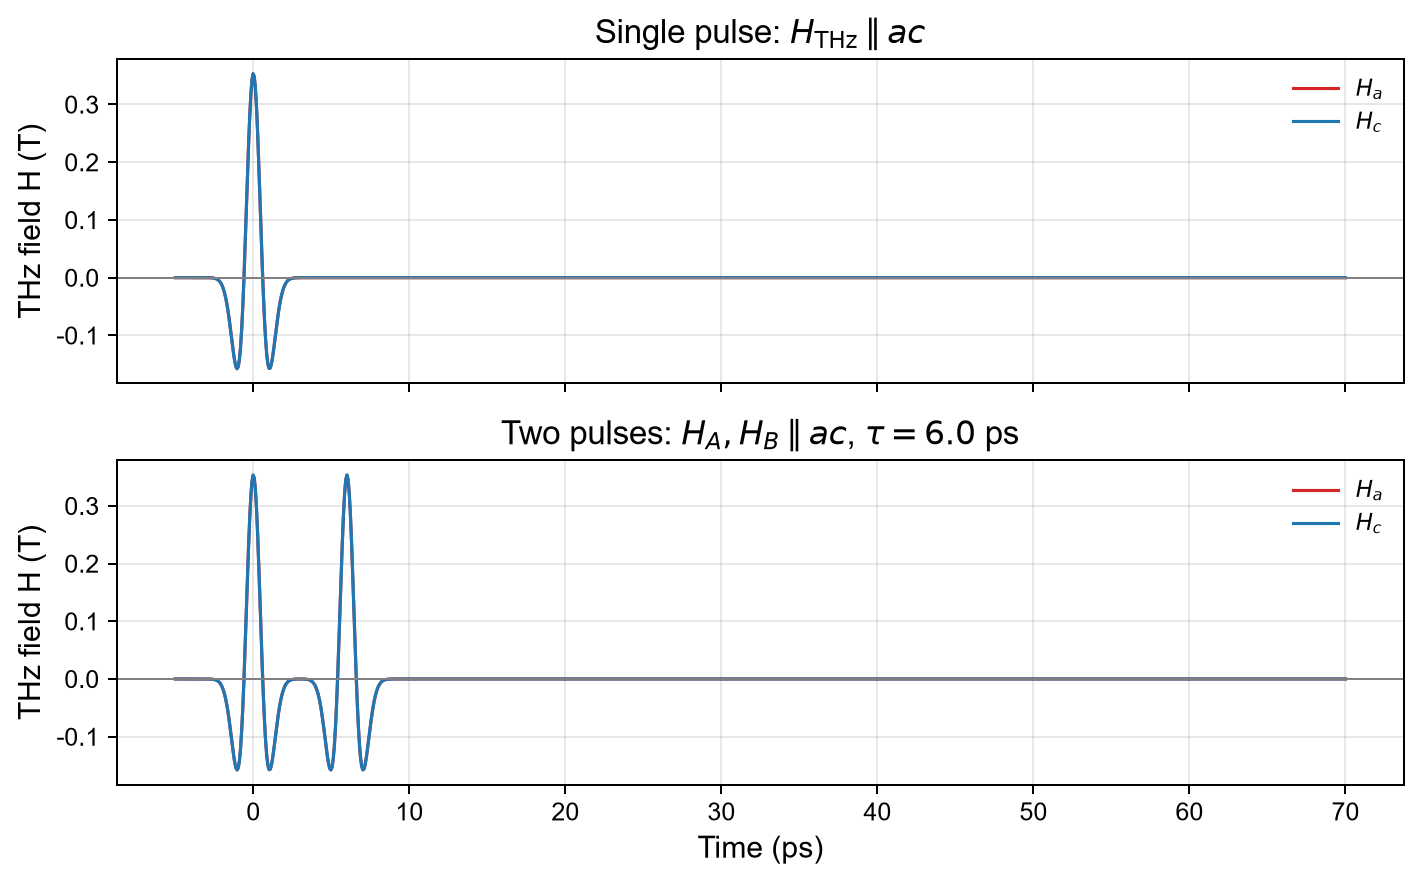

In [79]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.0), dpi=180, sharex=True)
plot_field_components(axes[0], time_list, H_single, title=r'Single pulse: $H_{\rm THz}\parallel ac$', xlabel=None)
plot_field_components(axes[1], time_list, H_two, title=rf'Two pulses: $H_A,H_B\parallel ac$, $\tau={tau_delay:.1f}$ ps')
fig.tight_layout()

## Single-pulse LLG simulation, $\alpha=0$

max spin-length error: 1.5987211554602254e-14


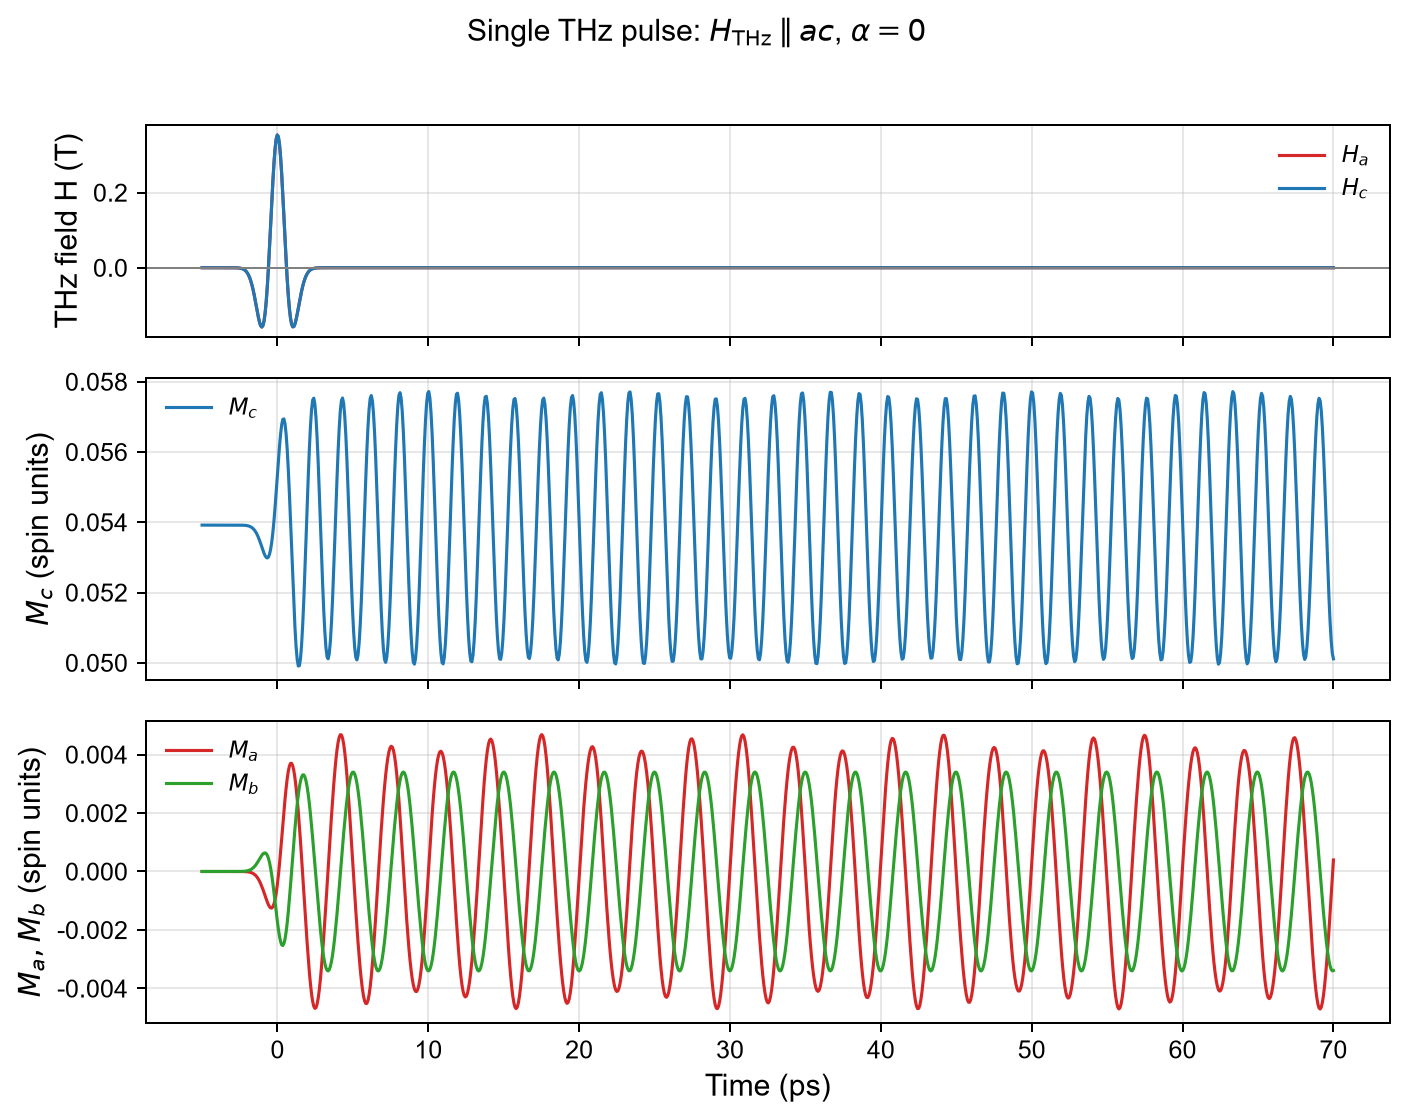

In [80]:
alpha = 0.0
single_result = run_llg(time_list, S1_eq, S2_eq, ham_params, alpha, single_pulse_params, d2gdt2_pulse, field_func=single_thz_pulse, **solver_options)
M_single = single_result['M']

print('max spin-length error:', max(
    np.max(np.abs(np.linalg.norm(single_result['S1'], axis=1) - ham_params['Stot'])),
    np.max(np.abs(np.linalg.norm(single_result['S2'], axis=1) - ham_params['Stot'])),
))

plot_magnetization_dynamics(time_list, M_single, pulse=H_single,
    title=r'Single THz pulse: $H_{\rm THz}\parallel ac$, $\alpha=0$',
    legend_config=LEGEND_STYLES['compact']);

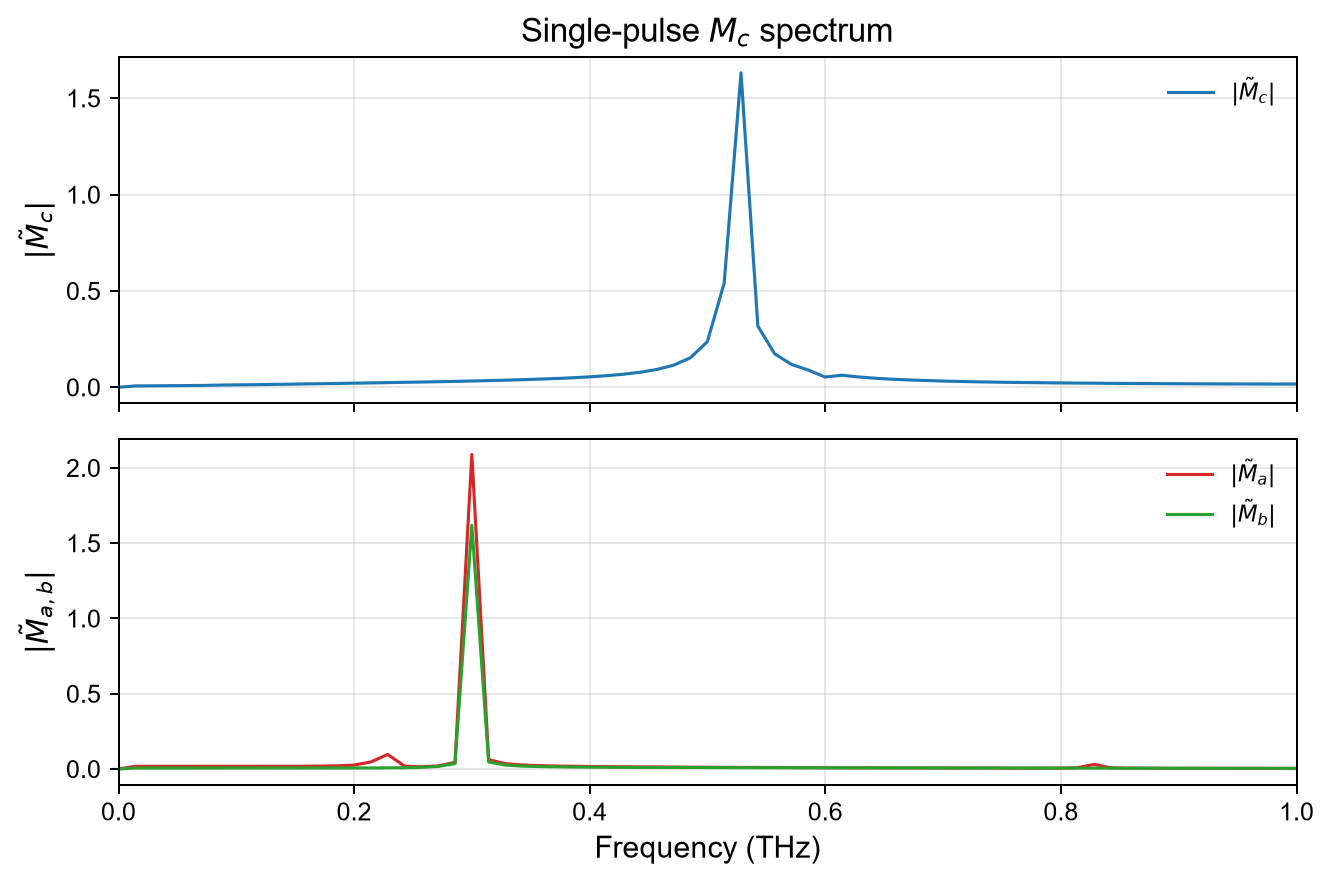

In [82]:
# FFT after the single pulse has decayed.
single_mask = time_list >= 0
f_single, _, A_single = rfft_spectrum(time_list[single_mask], M_single[single_mask], remove_mean=True)

fig, (ax_c, ax_ab) = plt.subplots(2, 1, figsize=(7.5, 5.0), dpi=180, sharex=True)

plot_time_series(ax_c, f_single, {r'$|\tilde M_c|$': A_single[:, 2]},
    styles=[PLOT_STYLES['component_c']], title=r'Single-pulse $M_c$ spectrum', xlabel=None, ylabel=r'$|\tilde M_c|$', xlim=(0, 1))

plot_time_series(ax_ab, f_single, {r'$|\tilde M_a|$': A_single[:, 0], r'$|\tilde M_b|$': A_single[:, 1]},
    styles=[PLOT_STYLES['component_a'], PLOT_STYLES['component_b']], xlabel='Frequency (THz)', ylabel=r'$|\tilde M_{a,b}|$', xlim=(0, 1))
fig.tight_layout()

## Two-pulse LLG simulation, $\alpha=0$

max spin-length error: 7.993605777301127e-15


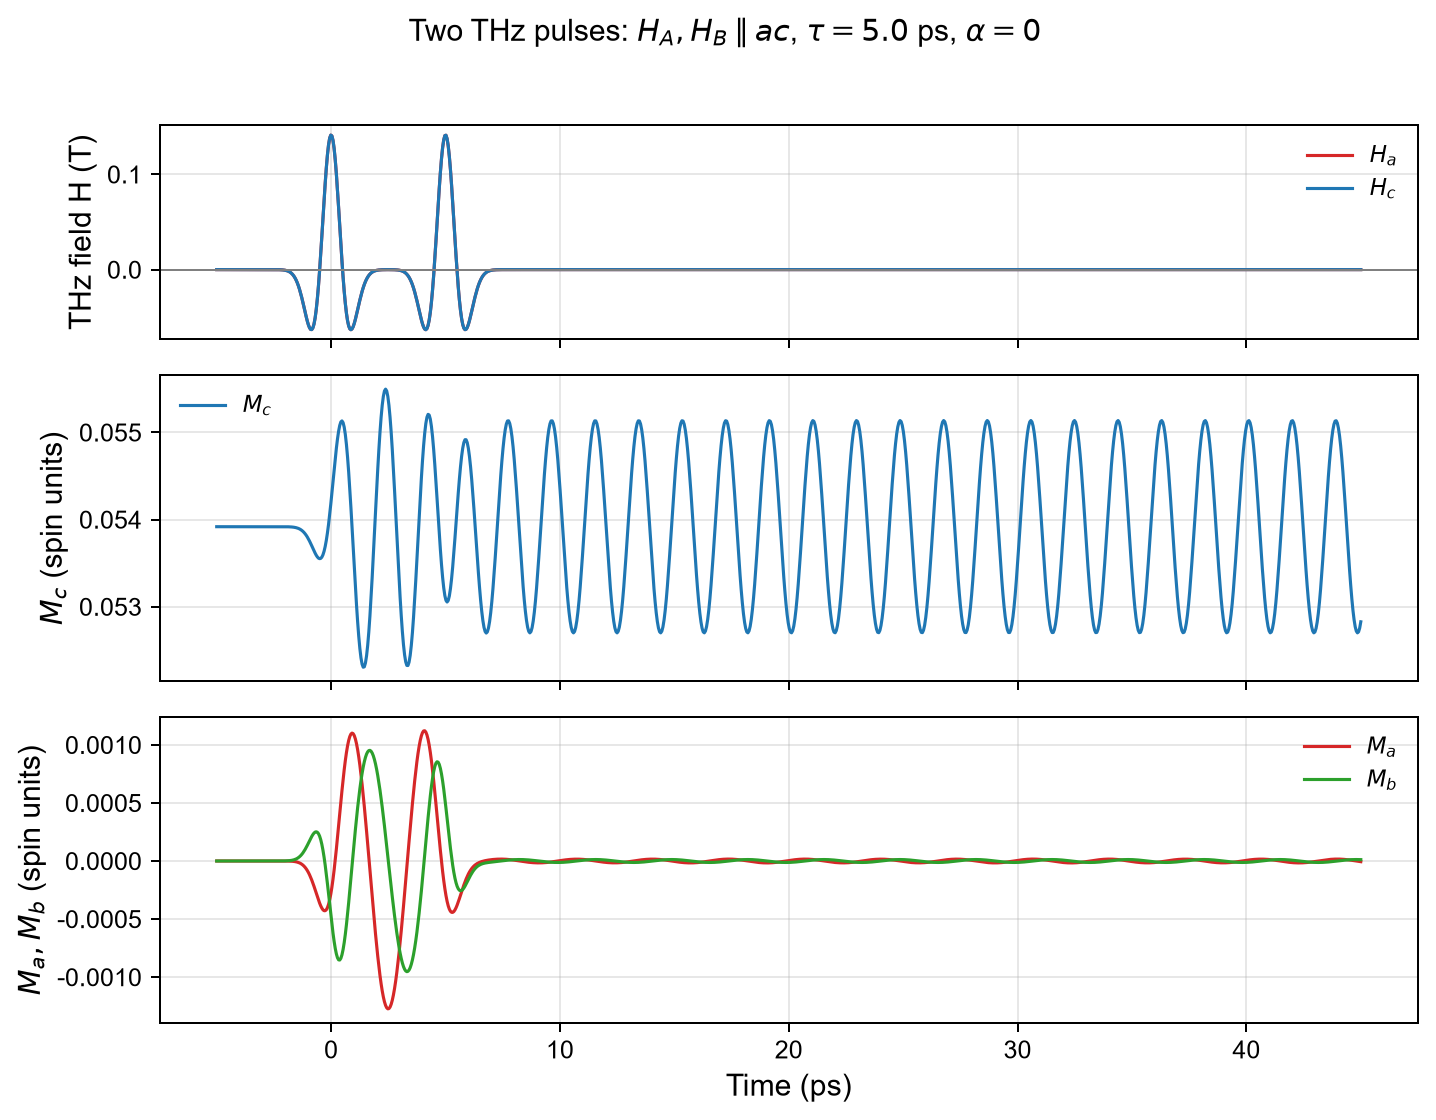

In [ ]:
two_result = run_llg(time, S1_eq, S2_eq, ham_params, alpha, two_pulse_params, d2gdt2_pulse, **solver_options)
M_two = two_result['M']

print('max spin-length error:', max(
    np.max(np.abs(np.linalg.norm(two_result['S1'], axis=1) - ham_params['Stot'])),
    np.max(np.abs(np.linalg.norm(two_result['S2'], axis=1) - ham_params['Stot'])),
))
plot_magnetization_dynamics(time, M_two, pulse=H_two,
    title=rf'Two THz pulses: $H_A,H_B\parallel ac$, $\tau={tau_delay:.1f}$ ps, $\alpha=0$',
    legend_config=LEGEND_STYLES['compact']);

single-pulse FFT spacing: 0.0233 THz
two-pulse FFT spacing: 0.0263 THz


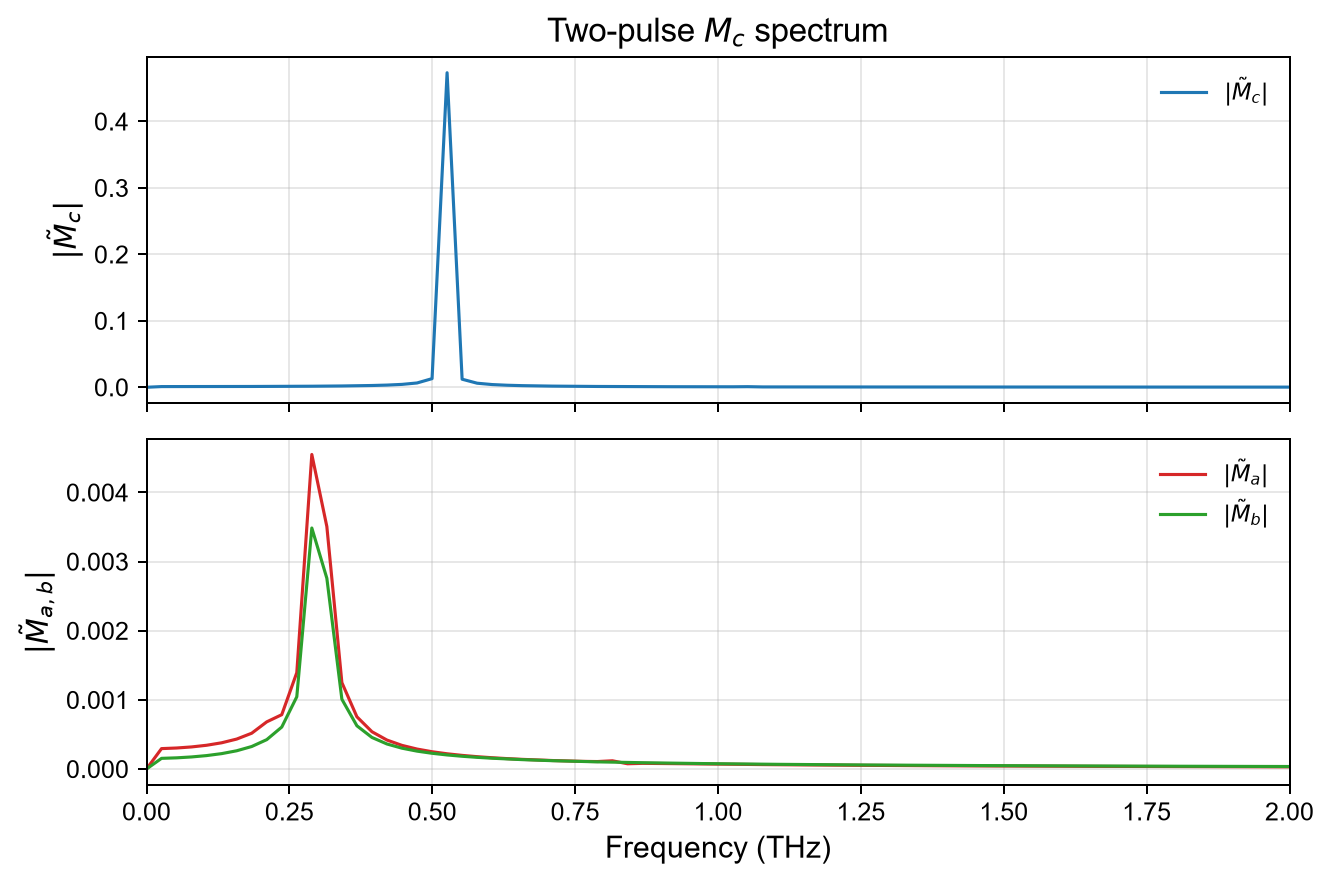

In [34]:
# FFT after pulse B has decayed.
two_mask = time >= tau_delay + 4*sigma
f_two, _, A_two = rfft_spectrum(time[two_mask], M_two[two_mask], remove_mean=True)
fig, (ax_c, ax_ab) = plt.subplots(2, 1, figsize=(7.5, 5.0), dpi=180, sharex=True)
plot_time_series(ax_c, f_two, {r'$|\tilde M_c|$': A_two[:, 2]},
    styles=[PLOT_STYLES['component_c']], title=r'Two-pulse $M_c$ spectrum', xlabel=None, ylabel=r'$|\tilde M_c|$', xlim=(0, 2))
plot_time_series(ax_ab, f_two, {r'$|\tilde M_a|$': A_two[:, 0], r'$|\tilde M_b|$': A_two[:, 1]},
    styles=[PLOT_STYLES['component_a'], PLOT_STYLES['component_b']], xlabel='Frequency (THz)', ylabel=r'$|\tilde M_{a,b}|$', xlim=(0, 2))
fig.tight_layout()

print(f'single-pulse FFT spacing: {f_single[1]-f_single[0]:.4f} THz')
print(f'two-pulse FFT spacing: {f_two[1]-f_two[0]:.4f} THz')